## Avaliação da classificação do modelo do EP1

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Carregar os arquivos
ideal = pd.read_excel("../data/test1-rotulado-para-teste-estatistico.xlsx")
previsoes = pd.read_excel("../resultados/test1_rotulado.xlsx")

# Conferir se os textos estão na mesma ordem
assert ideal["resp_text"].equals(previsoes["resp_text"]), \
    "Os textos não estão na mesma ordem!"

# Rótulos reais e previsões do modelo
y_real = ideal["clarity"]
y_pred = previsoes["clarity"]

classes = ["c1", "c234", "c5"]

# Calcular acurácia
acuracia = accuracy_score(y_real, y_pred)

print(f"Acurácia do modelo EP1: {acuracia:.2%}")

# Relatório de classificação
print("\nRelatório de classificação:")
print(classification_report(
    y_real,
    y_pred,
    labels=classes,
    zero_division=0
))

Acurácia do modelo EP1: 49.67%

Relatório de classificação:
              precision    recall  f1-score   support

          c1       0.52      0.49      0.51       300
        c234       0.44      0.44      0.44       300
          c5       0.53      0.55      0.54       300

    accuracy                           0.50       900
   macro avg       0.50      0.50      0.50       900
weighted avg       0.50      0.50      0.50       900



### Gráfico de erros por classe real
Visualizar erros e acertos do modelo por classe (em qual ele mais errou ou acertou)


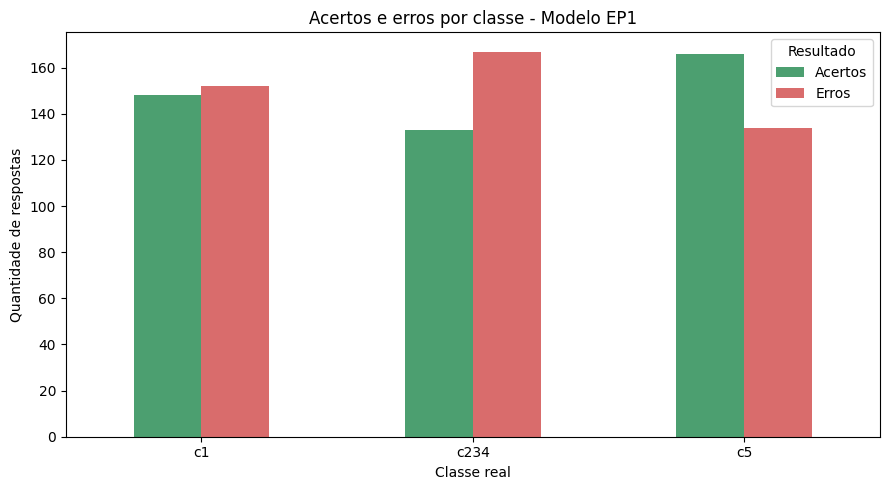

In [24]:
# Criar DataFrame para análise
resultado = pd.DataFrame({
    "real": y_real,
    "previsto": y_pred
})

resultado["correto"] = resultado["real"] == resultado["previsto"]

# Contabilizar acertos e erros por classe real
erros_por_classe = (
    resultado.groupby("real")["correto"]
    .value_counts()
    .unstack(fill_value=0)
    .reindex(classes, fill_value=0)
)

erros_por_classe = erros_por_classe.rename(
    columns={True: "Acertos", False: "Erros"}
)

erros_por_classe[["Acertos", "Erros"]].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#4C9F70", "#D96C6C"]
)

plt.title("Acertos e erros por classe - Modelo EP1")
plt.xlabel("Classe real")
plt.ylabel("Quantidade de respostas")
plt.xticks(rotation=0)
plt.legend(title="Resultado")
plt.tight_layout()
plt.show()

In [25]:
# Mostrar quantidade e percentual de acertos e erros por classe
resumo_classes = erros_por_classe.copy()

resumo_classes["Total"] = (
    resumo_classes["Acertos"] + resumo_classes["Erros"]
)

resumo_classes["% Acertos"] = (
    resumo_classes["Acertos"] / resumo_classes["Total"] * 100
).round(2)

resumo_classes["% Erros"] = (
    resumo_classes["Erros"] / resumo_classes["Total"] * 100
).round(2)

print("Desempenho por classe:")
display(resumo_classes)

Desempenho por classe:


correto,Erros,Acertos,Total,% Acertos,% Erros
real,,,,,
c1,152,148,300,49.33,50.67
c234,167,133,300,44.33,55.67
c5,134,166,300,55.33,44.67


### Visualizar exemplos dos erros
Mostra os textos que foram classificados incorretamente e permite identificar padrões nos erros

In [26]:
erros = resultado[resultado["correto"] == False].copy()

erros["texto"] = ideal.loc[erros.index, "resp_text"]

erros = erros[["texto", "real", "previsto"]]

# Mostrar alguns exemplos
pd.set_option("display.max_colwidth", 300)

display(erros.head(10))

,texto,real,previsto
0,"Prezada Hellen, Dentre as pesquisas domiciliares, a única que produz resultados para o nível municipal é o Censo Demográfico, que é realizado de 10 em 10 anos. Sendo assim, as últimas informações disponíveis para o tema Deficiência para o município de Varginha - MG são com base no Censo ...",c5,c234
1,"Senhor Francisco, O Serviço de Informações ao Cidadão do Ministério do Planejamento, Desenvolvimento e Gestão agradece o seu contato. Em atenção à sua solicitação, apresentamos, em anexo, a planilha solicitada esclarecendo que trata-se do período em que os pagamentos foram feitos via SIAPE, n...",c1,c234
6,"A informação solicitada encontra-se na página da UFF, no link http://www.uff.br/sites/default/files/quadro_de_referencia_dos_cargos_tecnico-administrativos_-_dezembro_de_2015.pdf Atenciosamente Equipe SIC",c5,c1
7,"Prezado (a) Cidadão (ã), 1.Conforme solicitação através do E-SIC, site CGU, informamos que: 1.1. Segue abaixo respostas para todos os questionamentos: 01) Do estoque total do débito inscrito na dívida ativa da união, qual a porcentagem e-ou valor cobrado e recuperado pela CAIXA por meio do ...",c1,c234
9,"Prezado Ssenhor, Em atendimento a sua solicitação, esclarecemos que a Central de Serviços Serpro (CSS) é o canal de comunicação dos clientes e usuários para receber, registrar, encaminhar e monitorar os acionamentos sobre questões de operacionalização de produtos e serviços. Na CSS, dar-se...",c234,c1
11,"Prezado Senhor, Em atenção ao seu pedido de informação, registrado em 04/03/2016, encaminhamos arquivo anexo com a resposta elaborada pela Unidade competente deste Ministério. Registre-se que, caso julgue conveniente, poderá apresentar recurso no prazo de 10 dias, via e-SIC (www.acessoainform...",c1,c234
12,"Prezado senhor, Em resposta a sua pergunta, gostaríamos de esclarecer que, desde 2003, com a criação do MTur - Ministério do Turismo, a Embratur (Instituto Brasileiro de Turismo) passou a ser responsável apenas pela promoção, marketing e apoio à comercialização dos destinos, serviços e produtos...",c234,c1
13,"Prezado Senhor, Esclarecemos que a Lei de Acesso á Informação não ampara a formulação de consultas, reclamações e denúncias, bem como pedidos de providências para a Administração Pública Federal ou solicitações de indenizações. Os pedidos devem veicular, única e exclusivamente, o acesso a ""dad...",c234,c1
14,"Prezada, seguem respostas: 1) De acordo com Decreto n&deg, 8.539, de 8 de outubro de 2015, que dispõe sobre o uso do meio eletrônico para a realização do processo administrativo no âmbito dos órgãos e das entidades da administração pública federal direta, autárquica e fundacional, a instituiç...",c5,c234
16,"Prezado Sr. Marcelo, Agradecemos seu contato com a Universidade Federal do Triângulo Mineiro (UFTM) pelo sistema e-SIC. Sobre a solicitação em comento cumpre-nos informar a V.Sa que o QRSTA da UFTM pode ser encontrado no sítio a seguir: http://www.uftm.edu.br/prorh/publicacoes/quadro-de-refer...",c234,c5


### Combinações de classes geraram erros
Matriz de confusão em tabela

In [27]:
erros_combinacoes = (
    erros.groupby(["real", "previsto"])
    .size()
    .reset_index(name="quantidade")
    .sort_values("quantidade", ascending=False)
)

display(erros_combinacoes)

,real,previsto,quantidade
0,c1,c234,85
2,c234,c1,85
5,c5,c234,83
3,c234,c5,82
1,c1,c5,67
4,c5,c1,51


### Matriz de confusão

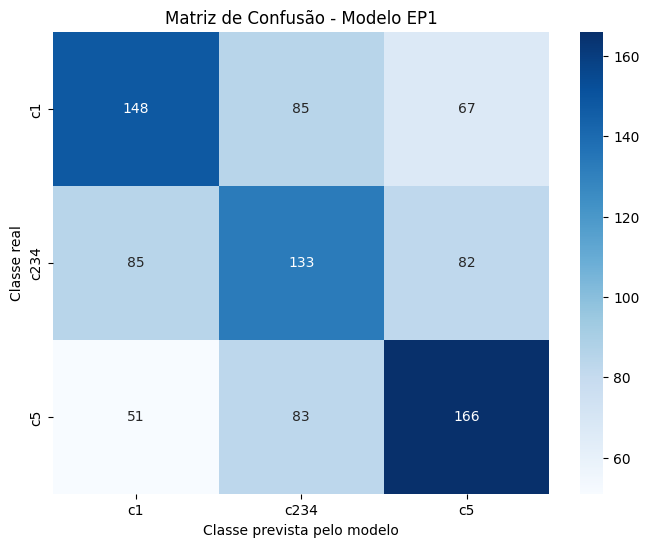

In [28]:
matriz = confusion_matrix(y_real, y_pred, labels=classes)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Matriz de Confusão - Modelo EP1")
plt.xlabel("Classe prevista pelo modelo")
plt.ylabel("Classe real")

plt.show()